# Experiment 3 — Sampling Methods (Titanic Dataset)

**Covers:** Simple random, stratified and cluster sampling, category proportions, population/sample comparison, graph and CSV export.

**Dataset:** **Titanic** – `train.csv` from the Kaggle Titanic competition ([kaggle.com/c/titanic](https://www.kaggle.com/competitions/titanic/data)), 891 passengers, columns `PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked`.

**Data file:** keep `train.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\train.csv")`).

**Remember:** sample() → groupby().sample() → choice() + isin() → Compare → Save.

`Embarked` (port) is used as a classroom stand-in for geographical clusters.

## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("train.csv")

## 0. Population

In [2]:
N = len(df)
n = int(0.2 * N)
mean = df["Fare"].mean()

print("Population:", N, "Sample:", n, "Mean:", mean)

Population: 891 Sample: 178 Mean: 32.204207968574636


## 1. Simple random sampling

In [3]:
srs = df.sample(n=n, random_state=42)
print(srs.head())
print(df.sample(n=n, random_state=10).head())

     PassengerId  Survived  Pclass  \
709          710         1       3   
439          440         0       2   
840          841         0       3   
720          721         1       2   
39            40         1       3   

                                                  Name     Sex   Age  SibSp  \
709  Moubarek, Master. Halim Gonios ("William George")    male   NaN      1   
439             Kvillner, Mr. Johan Henrik Johannesson    male  31.0      0   
840                        Alhomaki, Mr. Ilmari Rudolf    male  20.0      0   
720                  Harper, Miss. Annie Jessie "Nina"  female   6.0      0   
39                         Nicola-Yarred, Miss. Jamila  female  14.0      1   

     Parch            Ticket     Fare Cabin Embarked  
709      1              2661  15.2458   NaN        C  
439      0        C.A. 18723  10.5000   NaN        S  
840      0  SOTON/O2 3101287   7.9250   NaN        S  
720      1            248727  33.0000   NaN        S  
39       0           

## 2. Stratified sampling using `Sex`

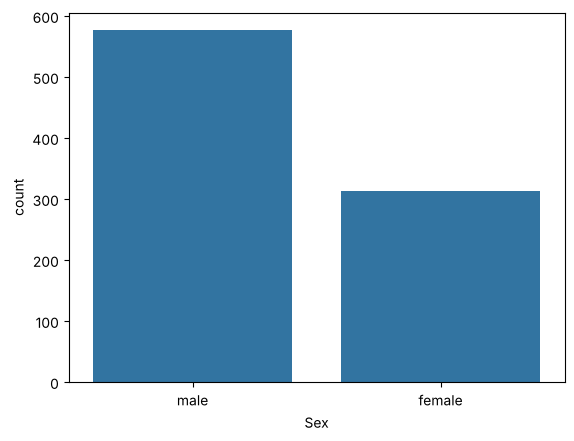

        Population %   Sample %
Sex                            
male       64.758698  64.606742
female     35.241302  35.393258


In [4]:
sns.countplot(data=df, x="Sex")
plt.show()

strat = df.groupby("Sex", group_keys=False).sample(
    frac=0.2, random_state=42
)

print(pd.DataFrame({
    "Population %": df["Sex"].value_counts(normalize=True) * 100,
    "Sample %": strat["Sex"].value_counts(normalize=True) * 100
}))

## 3. Cluster sampling using `Embarked`

In [5]:
clusters = df["Embarked"].dropna().unique()
selected = np.random.default_rng(42).choice(
    clusters, size=max(1, int(0.3 * len(clusters))), replace=False
)
cluster = df[df["Embarked"].isin(selected)]
print("All clusters:", clusters)
print("Selected clusters:", selected)
print("Cluster sample size:", len(cluster))

All clusters: ['S' 'C' 'Q']
Selected clusters: ['S']
Cluster sample size: 644


## 4. Comparison table

In [6]:
samples = {"SRS": srs, "Stratified": strat, "Cluster": cluster}

result = pd.DataFrame({
    "Size": [len(s) for s in samples.values()],
    "Mean": [s["Fare"].mean() for s in samples.values()]
}, index=samples.keys())

result["Difference"] = result["Mean"] - mean
print(result)

            Size       Mean  Difference
SRS          178  30.763038   -1.441170
Stratified   178  30.954515   -1.249693
Cluster      644  27.079812   -5.124396


## 5. Graph

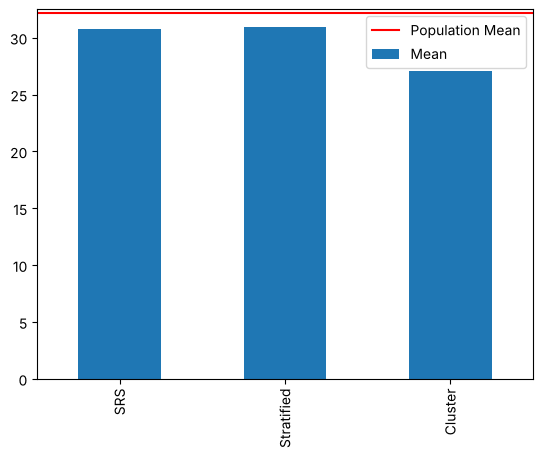

In [7]:
result["Mean"].plot(kind="bar")
plt.axhline(mean, color="red", label="Population Mean")
plt.legend()
plt.show()

## 6. Save

In [8]:
for name, sample in samples.items():
    sample.to_csv(name + ".csv", index=False)
    print("Saved", name + ".csv")

Saved SRS.csv
Saved Stratified.csv
Saved Cluster.csv


## Result / Conclusion
- Population mean `Fare` = 32.20 (N = 891, sample size 178).
- **Stratified** sampling by sex keeps the male/female split (64.8% / 35.2%) and gives mean 30.95 (error −1.25).
- **Simple random** sampling gives 30.76 (error −1.44).
- **Cluster** sampling selected only port S (644 passengers) with mean 27.08 (error −5.12): passengers from Southampton paid lower fares, so one port does not represent the whole ship.